explore how jobbing would work in the extremes of a spread. main thing would be trying to evaluate a 'fair' price (or fair value), trade accordingly, and then see what happens after getting filled. 

In [1]:
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import load_data

In [2]:
hl_hype = load_data.get_md(
    'HYPERLIQUID',
    'HYPE-USD-PERP',
    'book')
    
bin_hype = load_data.get_md(
    'BINANCE_FUTURES',
    'HYPE-USDT-PERP',
    'book')

In [23]:
# Select only the columns you need
b = (
    bin_hype[
        ["mid", "bid", "ask", "bid_size", "ask_size", "imbalance", "microprice"]
    ]
    .rename(columns={
        "mid": "bin_mid",
        "bid": "bin_bid",
        "ask": "bin_ask",
        "bid_size": "bid_size_bin",
        "ask_size": "ask_size_bin",
        "imbalance": "imbalance_bin",
        "microprice": "microprice_bin"
    })
    .sort_index()
)

h = (
    hl_hype[
        ["mid", "bid", "ask", "bid_size", "ask_size", "imbalance", "microprice"]
    ]
    .rename(columns={
        "mid": "hl_mid",
        "bid": "hl_bid",
        "ask": "hl_ask",
        "bid_size": "bid_size_hl",
        "ask_size": "ask_size_hl",
        "imbalance": "imbalance_hl",
        "microprice": "microprice_hl"
    })
    .sort_index()
)

In [24]:
df = (
    pd.concat([b, h], axis=1, join="outer")
    .sort_index()
    .fillna(0)
)

df

/tmp/ipykernel_1829/1377636184.py:2: Pandas4Warning: Sorting by default when concatenating all DatetimeIndex is deprecated.  In the future, pandas will respect the default of `sort=False`. Specify `sort=True` or `sort=False` to silence this message. If you see this warnings when not directly calling concat, report a bug to pandas.
  pd.concat([b, h], axis=1, join="outer")


,bin_mid,bin_bid,bin_ask,bid_size_bin,ask_size_bin,imbalance_bin,microprice_bin,hl_mid,hl_bid,hl_ask,bid_size_hl,ask_size_hl,imbalance_hl,microprice_hl
datetime,,,,,,,,,,,,,,
2026-09-29 03:16:28.325776815+00:00,0.0000,0.000,0.000,0.00,0.00,0.000000,0.000000,86.2465,86.246,86.247,173.24,0.57,0.993441,86.246997
2026-09-29 03:16:28.715247393+00:00,86.2075,86.207,86.208,0.12,67.31,-0.996441,86.207002,0.0000,0.000,0.000,0.00,0.00,0.000000,0.000000
2026-09-29 03:16:28.789179325+00:00,86.2055,86.205,86.206,29.09,30.13,-0.017562,86.205491,0.0000,0.000,0.000,0.00,0.00,0.000000,0.000000
2026-09-29 03:16:28.890801668+00:00,86.2055,86.205,86.206,29.09,108.38,-0.576780,86.205212,0.0000,0.000,0.000,0.00,0.00,0.000000,0.000000
2026-09-29 03:16:28.993021011+00:00,86.2055,86.205,86.206,29.09,185.64,-0.729055,86.205135,0.0000,0.000,0.000,0.00,0.00,0.000000,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2026-10-09 10:59:30.721457481+00:00,0.0000,0.000,0.000,0.00,0.00,0.000000,0.000000,85.7005,85.700,85.701,54.16,23.14,0.401294,85.700701
2026-10-09 10:59:35.738445520+00:00,0.0000,0.000,0.000,0.00,0.00,0.000000,0.000000,85.7125,85.712,85.713,26.98,145.60,-0.687333,85.712156
2026-10-09 10:59:41.082471371+00:00,0.0000,0.000,0.000,0.00,0.00,0.000000,0.000000,85.7125,85.712,85.713,45.96,7.00,0.735650,85.712868


In [16]:
df['microprice_spread'] = df['hl_microprice'] - df['bin_microprice']
df['mid_spread'] = df['hl_mid'] - df['bin_mid']
df.head()

,bin_mid,bin_bid,bin_ask,bin_bid_size,bin_ask_size,bin_imbalance,bin_microprice,hl_mid,hl_bid,hl_ask,hl_bid_size,hl_ask_size,hl_imbalance,hl_microprice,microprice_spread,mid_spread
datetime,,,,,,,,,,,,,,,,
2026-09-29 03:16:28.325776815+00:00,0.0000,0.000,0.000,0.00,0.00,0.000000,0.000000,86.2465,86.246,86.247,173.24,0.57,0.993441,86.246997,86.246997,86.2465
2026-09-29 03:16:28.715247393+00:00,86.2075,86.207,86.208,0.12,67.31,-0.996441,86.207002,0.0000,0.000,0.000,0.00,0.00,0.000000,0.000000,-86.207002,-86.2075
2026-09-29 03:16:28.789179325+00:00,86.2055,86.205,86.206,29.09,30.13,-0.017562,86.205491,0.0000,0.000,0.000,0.00,0.00,0.000000,0.000000,-86.205491,-86.2055
2026-09-29 03:16:28.890801668+00:00,86.2055,86.205,86.206,29.09,108.38,-0.576780,86.205212,0.0000,0.000,0.000,0.00,0.00,0.000000,0.000000,-86.205212,-86.2055
2026-09-29 03:16:28.993021011+00:00,86.2055,86.205,86.206,29.09,185.64,-0.729055,86.205135,0.0000,0.000,0.000,0.00,0.00,0.000000,0.000000,-86.205135,-86.2055


In [21]:
df['microprice_spread']

datetime
2026-09-29 03:16:28.325776815+00:00    86.246997
2026-09-29 03:16:28.715247393+00:00   -86.207002
2026-09-29 03:16:28.789179325+00:00   -86.205491
2026-09-29 03:16:28.890801668+00:00   -86.205212
2026-09-29 03:16:28.993021011+00:00   -86.205135
                                         ...    
2026-10-09 10:59:30.721457481+00:00    85.700701
2026-10-09 10:59:35.738445520+00:00    85.712156
2026-10-09 10:59:41.082471371+00:00    85.712868
2026-10-09 10:59:46.582511425+00:00    85.706317
2026-10-09 10:59:51.611354828+00:00    85.716150
Name: microprice_spread, Length: 6869586, dtype: float64

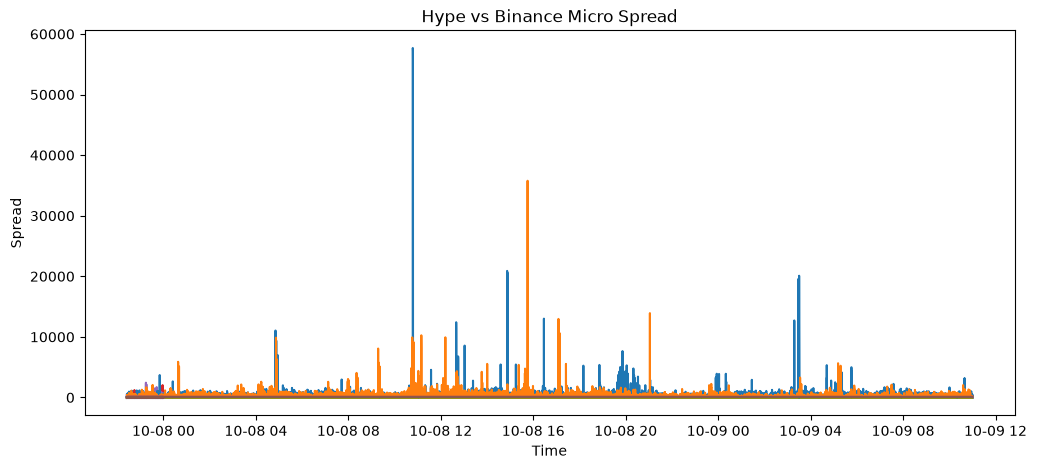

In [19]:
plot = df[df['microprice_spread'] != 0].iloc[-75_000:]

fig, ax = plt.subplots(figsize = (12,5))

ax.plot(plot.index, plot.to_numpy())
ax.set_title("Hype vs Binance Micro Spread")
ax.set_xlabel("Time")
ax.set_ylabel("Spread")

plt.show()

need to figure out how profitable/cost analysis of actually trading the microprice spread

In [41]:
from spread_cost import plot_pnl, cost_breakdown

events           : 6,869,586
span             : 891,803 s (247.72 h)
gap mean/median  : 129.8 / 102.7 ms
gap min/max      : 0.0 / 3590779.3 ms
gap CV           : 15.659   (0 = perfect grid, 1 = Poisson)
modal gap        : 102.0 ms (0.1% of gaps)

VERDICT: IRREGULAR
Genuinely irregular arrivals. The non-uniform transform is the right tool.
Hyperliquid quote-change events : 296,748
Binance quote-change events     : 5,498,697
span                            : 247.72 h
STEP 1 - analytic screen (loose, do not quote)
               period_s       n          cycles measurable         R           z         p   p_bonf  significant     phase_s
100 ms (feed?)      0.1  296748  8918028.961074       True  0.007163   15.227006       0.0  0.00000         True     0.06791
250 ms (feed?)     0.25  296748   3567211.58443       True  0.018813   105.03044       0.0  0.00000         True    0.053952
500 ms (feed?)      0.5  296748  1783605.792215       True  0.033432  331.666983       0.0  0.00000         

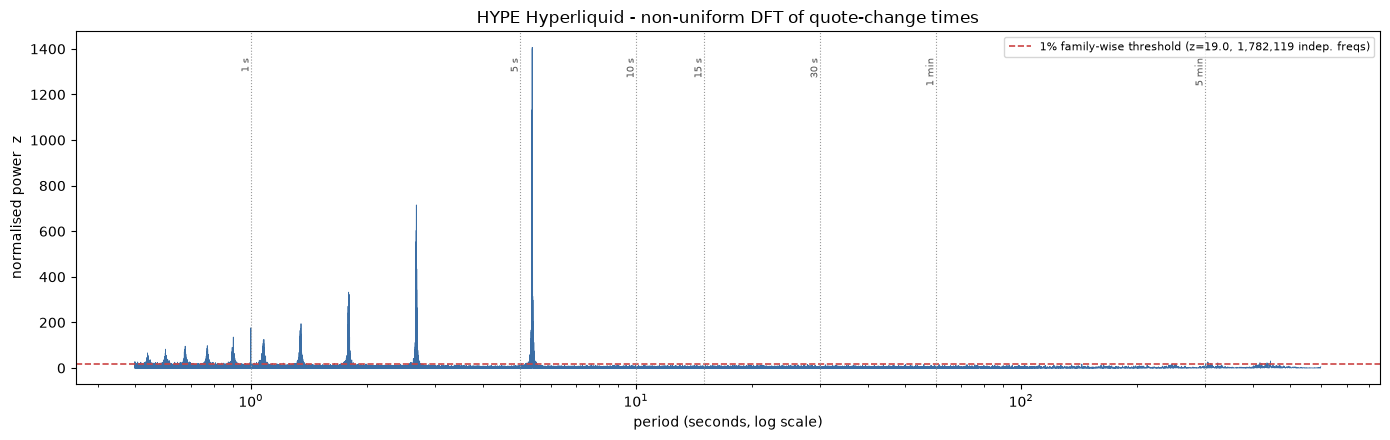

     1 s : peak z= 176.34  neighbours=  1.59  contrast=110.97x
    10 s : peak z=   1.86  neighbours=  1.01  contrast= 1.84x
    60 s : peak z=   4.32  neighbours=  1.23  contrast= 3.51x
   300 s : peak z=   5.33  neighbours=  1.28  contrast= 4.17x


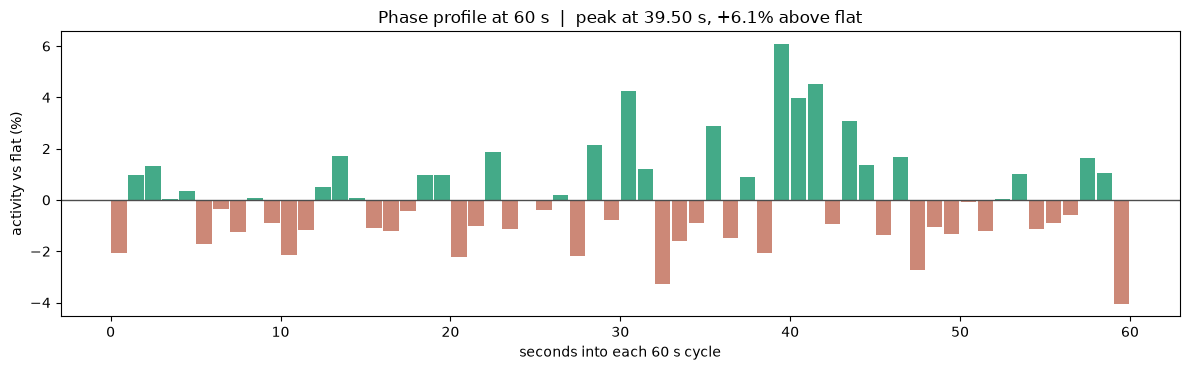

chi2 = 110 on 59 dof
busiest slice: 39.5 s into the minute, +6.1% above flat

NOTE the wrap: activity at the top of the minute splits across the
first and last bins, so a peak at 59.x s and a peak at 0.x s are the
same event. Lopez de Prado's natural-gas finding was exactly this -
a spike in the first second of every minute.
               hl_period_s      hl_R  hl_phase_s hl_excess_pct hl_contrast hl_p_shuffle hl_p_worst_block hl_confirmed bin_period_s     bin_R bin_phase_s bin_excess_pct bin_contrast bin_p_shuffle bin_p_worst_block bin_confirmed
100 ms (feed?)         0.1  0.007163     0.06791      4.060011    0.141123     0.002494         0.002494        False          0.1  0.020191    0.064152       6.323153   111.166904      0.002494          0.002494          True
250 ms (feed?)        0.25  0.018813    0.053952      4.371386   34.654503     0.002494         0.002494         True         0.25  0.013061    0.125841       4.598453   112.155268      0.002494          0.002494       

In [25]:
"""
Paste-ready cells for the non-uniform FFT / clock-alignment analysis on HYPE.

Put hft_clock.py next to load_data.py, then paste the blocks below in order.

CELL 1 can end the project in ten seconds, and that is the point. Do not skip
it to get to the spectrum.
"""

# %% ------------------------------------------------------------------
# CELL 1 - THE GATE: is this series irregular enough for any of this?
#
# Your head() showed timestamps 150 ms apart to the millisecond. If that is
# a resample, the arrival times that carry the TWAP signature are gone and
# everything below measures your resampler. Find out before going further.
# ---------------------------------------------------------------------
import importlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import hft_clock as hc
importlib.reload(hc)

samp = hc.sampling_report(df.index)

# If the verdict is UNIFORM, stop here and go back to the raw feed. In
# cryptofeed that means the un-resampled L2_BOOK callback timestamps, and
# ideally the TRADES callback, which is what Lopez de Prado was reading.


# %% ------------------------------------------------------------------
# CELL 2 - build the activity index
#
# Quote changes are the proxy available from a book frame. They are NOT the
# same thing as trades: they include everyone's passive repricing and the
# venue's own housekeeping. A TWAP's signature lives in trade arrivals.
# Use trade_events() instead the moment you have the trade feed.
# ---------------------------------------------------------------------
t_hl, w_hl, mask_hl = hc.activity_events(df, venue="hl", kind="quote_change")
t_bn, w_bn, mask_bn = hc.activity_events(df, venue="bin", kind="quote_change")

print(f"Hyperliquid quote-change events : {t_hl.size:,}")
print(f"Binance quote-change events     : {t_bn.size:,}")
print(f"span                            : {t_hl.max()/3600:.2f} h")

# when you have trades:
#   t, w = hc.trade_events(trades_df, size_col="amount", weight="count")


# %% ------------------------------------------------------------------
# CELL 3 - the full pipeline, in the defensible order
#
#   screen the named periods  ->  block-permutation null  ->  verdict
#
# Read the columns in this order: contrast, excess_pct, R, then the p-values
# last. On simulated data where I knew the answer, contrast separated a real
# 60 s schedule (3.5x) from pure burstiness (0.6x) cleanly, and the p-values
# did not separate them at all.
# ---------------------------------------------------------------------
res_hl = hc.run_analysis(t_hl, n_iter=400)


# %% ------------------------------------------------------------------
# CELL 4 - THE TEST THAT SETTLES IT
#
# Everything above can be fooled by bursty flow. This cannot, easily: a
# scheduled algorithm fires at the SAME PHASE in every window, because it is
# a machine. A peak thrown up by clustering lands somewhere different each
# time.
#
# phase_agreement > 0.7 is the bar. On my calibration run a planted 60 s
# schedule scored 0.82 and three different spurious peaks scored 0.48-0.67.
# ---------------------------------------------------------------------
confirmed = res_hl["verdict"]
confirmed = confirmed[confirmed["confirmed"].astype(bool)] \
    if len(confirmed) else confirmed

for name, row in confirmed.iterrows():
    P = float(row["period_s"])
    frame, meta = hc.stability_check(t_hl, P, n_windows=6)
    print(f"\n=== {name} ({P:g} s) ===")
    print(frame.to_string())
    print(f"phase agreement : {meta['phase_agreement']:.3f}")
    print(f"mean phase      : {meta['mean_phase_s']:.2f} s into the cycle")
    print(f"-> {meta['verdict']}")


# %% ------------------------------------------------------------------
# CELL 5 - the spectrum, with the threshold drawn on it
#
# This is the picture from the paper. Note the red line: over a long sample
# the periodogram has millions of independent frequencies, and the biggest
# of millions of noise peaks is large. Anything under the line is noise no
# matter how sharp it looks.
# ---------------------------------------------------------------------
band, info = hc.scan_band(t_hl, p_lo=0.5, p_hi=600, bins_per_period=20)
print({k: (round(v, 4) if isinstance(v, float) else v)
       for k, v in info.items()})

# confidence check on the gridded transform vs the exact non-uniform sum
print("\ngridded vs exact:")
print(hc.verify_grid(t_hl, band, n_check=5).to_string())

fig, ax = plt.subplots(figsize=(14, 4.5))
hc.plot_spectrum(band, info, ax=ax,
                 title="HYPE Hyperliquid - non-uniform DFT of quote-change times")
plt.tight_layout(); plt.show()

# Lopez de Prado's actual claim was LOCAL - the once-per-minute frequency is
# high relative to its NEIGHBOURS. That comparison is immune to any broad
# slope in the spectrum and carries almost no multiplicity burden.
for P in (1.0, 10.0, 60.0, 300.0):
    lc = hc.local_contrast(band, P)
    print(f"{P:>6.0f} s : peak z={lc['peak_z']:7.2f}  "
          f"neighbours={lc['neighbour_median']:6.2f}  "
          f"contrast={lc['contrast']:5.2f}x")


# %% ------------------------------------------------------------------
# CELL 6 - the plot a trader will read without being taught what a
#          periodogram is
# ---------------------------------------------------------------------
PERIOD = 60.0

prof, meta = hc.phase_profile(t_hl, PERIOD, n_bins=60)
fig, ax = plt.subplots(figsize=(12, 3.8))
hc.plot_phase(prof, meta, PERIOD, ax=ax)
plt.tight_layout(); plt.show()

print(f"chi2 = {meta['chi2']:.0f} on {meta['dof']} dof")
print(f"busiest slice: {meta['peak_second']:.1f} s into the minute, "
      f"{meta['excess_max']*100:+.1f}% above flat")
print("\nNOTE the wrap: activity at the top of the minute splits across the\n"
      "first and last bins, so a peak at 59.x s and a peak at 0.x s are the\n"
      "same event. Lopez de Prado's natural-gas finding was exactly this -\n"
      "a spike in the first second of every minute.")


# %% ------------------------------------------------------------------
# CELL 7 - THE CONTROL THAT MATTERS MOST ON CRYPTO BOOK DATA
#
# Binance pushes depth diffs on a fixed 100/250/500 ms websocket cadence.
# Hyperliquid pushes on change. So a hard peak in the Binance series at a
# round sub-second period is the STREAM, not a trader.
#
# Run both venues and compare. A peak on one venue only, at its own push
# interval, is plumbing. A peak at the same period AND the same phase on
# both venues is something trading across both - which is the only version
# of this that is worth anything to your desk.
# ---------------------------------------------------------------------
res_bn = hc.run_analysis(t_bn, n_iter=400, verbose=False)

both = pd.concat([
    res_hl["verdict"].add_prefix("hl_") if len(res_hl["verdict"]) else pd.DataFrame(),
    res_bn["verdict"].add_prefix("bin_") if len(res_bn["verdict"]) else pd.DataFrame(),
], axis=1)
print(both.round(4).to_string())

print("\nphase comparison on anything confirmed on both venues:")
for name in both.index:
    if both.get("hl_confirmed", pd.Series()).get(name) and \
       both.get("bin_confirmed", pd.Series()).get(name):
        P = float(both.loc[name, "hl_period_s"])
        _, m_hl = hc.stability_check(t_hl, P)
        _, m_bn = hc.stability_check(t_bn, P)
        print(f"  {name}: HL phase {m_hl['mean_phase_s']:.2f}s "
              f"(agree {m_hl['phase_agreement']:.2f})  |  "
              f"BIN phase {m_bn['mean_phase_s']:.2f}s "
              f"(agree {m_bn['phase_agreement']:.2f})")

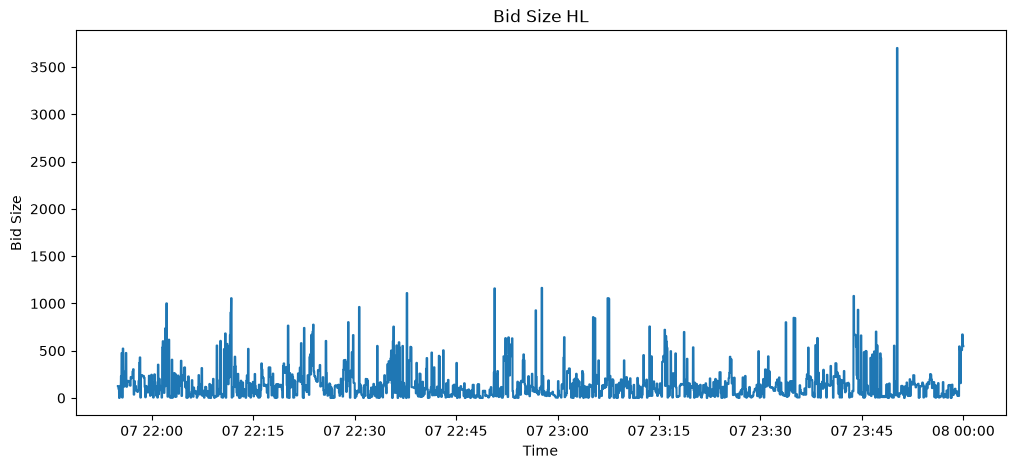

In [17]:
plot = df['bid_size_hl'].iloc[-50_000:] 

fig, ax = plt.subplots(figsize = (12,5))

ax.plot(plot.index, plot.to_numpy())
ax.set_title("Bid Size HL")
ax.set_xlabel("Time")
ax.set_ylabel("Bid Size")

plt.show()

In [18]:
df['bid_size_hl'].describe()

count    5.105409e+06
mean     1.848723e+02
std      4.981655e+02
min      1.000000e-02
25%      1.361000e+01
50%      7.240000e+01
75%      1.988400e+02
max      6.325514e+04
Name: bid_size_hl, dtype: float64

In [27]:
positions = np.flatnonzero((df["bid_size_hl"] > 720).to_numpy())
next_positions = sorted({
    row
    for position in positions
    for row in range(position + 1, min(position + 11, len(df)))
})

df_bids_split = df.iloc[next_positions]

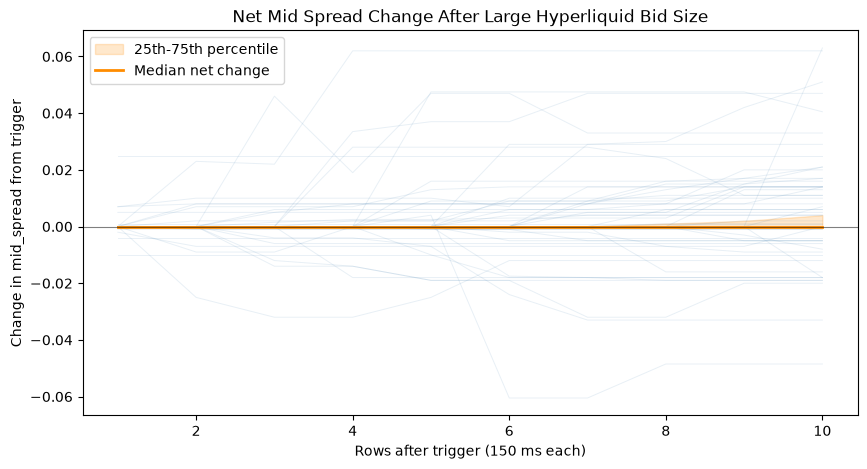

,trigger_bid_size,trigger_mid_spread,+1,+2,+3,+4,+5,+6,+7,+8,+9,+10
trigger_time,,,,,,,,,,,,
2026-09-29 03:19:45.300000+00:00,833.41,-0.0395,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
2026-09-29 03:19:45.450000+00:00,833.41,-0.0395,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
2026-09-29 03:19:45.600000+00:00,833.41,-0.0395,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
2026-09-29 03:19:45.750000+00:00,833.41,-0.0395,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
2026-09-29 03:19:45.900000+00:00,833.41,-0.0395,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
...,...,...,...,...,...,...,...,...,...,...,...,...
2026-10-07 23:50:14.850000+00:00,3701.08,0.0130,0.000,0.000,0.000,0.000,-0.036,-0.036,-0.036,-0.036,-0.036,-0.036
2026-10-07 23:50:15+00:00,3701.08,0.0130,0.000,0.000,0.000,-0.036,-0.036,-0.036,-0.036,-0.036,-0.036,-0.036
2026-10-07 23:50:15.150000+00:00,3701.08,0.0130,0.000,0.000,-0.036,-0.036,-0.036,-0.036,-0.036,-0.036,-0.036,-0.036


In [33]:
import numpy as np

trigger_positions = np.flatnonzero(df["bid_size_hl"].gt(720).to_numpy())
trigger_times = df.index[trigger_positions]
trigger_mid_spread = df["mid_spread"].iloc[trigger_positions].to_numpy()

# Each row is a trigger; +1 through +10 are net changes from the trigger spread.
mid_spread_after_triggers = pd.DataFrame(index=trigger_times)
mid_spread_after_triggers.index.name = "trigger_time"
mid_spread_after_triggers["trigger_bid_size"] = df["bid_size_hl"].iloc[trigger_positions].to_numpy()
mid_spread_after_triggers["trigger_mid_spread"] = trigger_mid_spread

for step in range(1, 11):
    valid = trigger_positions + step < len(df)
    future_mid_spread = df["mid_spread"].iloc[trigger_positions[valid] + step].to_numpy()
    mid_spread_after_triggers[f"+{step}"] = pd.Series(
        future_mid_spread - trigger_mid_spread[valid],
        index=trigger_times[valid],
    )

spread_paths = mid_spread_after_triggers[[f"+{step}" for step in range(1, 11)]]
horizons = np.arange(1, 11)
median_path = spread_paths.median()
low_path = spread_paths.quantile(0.25)
high_path = spread_paths.quantile(0.75)
sample_paths = spread_paths.sample(n=min(100, len(spread_paths)), random_state=0)

fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(horizons, sample_paths.to_numpy().T, color="steelblue", alpha=0.12, linewidth=0.7)
ax.fill_between(horizons, low_path.to_numpy(), high_path.to_numpy(), color="darkorange", alpha=0.2, label="25th-75th percentile")
ax.plot(horizons, median_path.to_numpy(), color="darkorange", linewidth=2, label="Median net change")
ax.axhline(0, color="black", linewidth=0.8, alpha=0.5)
ax.set(title="Net Mid Spread Change After Large Hyperliquid Bid Size", xlabel="Rows after trigger (150 ms each)", ylabel="Change in mid_spread from trigger")
ax.legend()
plt.show()

mid_spread_after_triggers

In [35]:
bid_over_threshold = df["bid_size_hl"].gt(720)
trigger_positions = np.flatnonzero(
    (bid_over_threshold & ~bid_over_threshold.shift(fill_value=False)).to_numpy()
)

In [36]:
trigger_positions

array([   1311,    3326,   10009, ..., 5098908, 5099160, 5101476],
      shape=(3422,))